[← Previous: Modelling](03_modelling.ipynb)

# Result analysis

## Validation performance

We compare the selected models using the final-epoch validation predictions. Here, **mean IoU averages the 15 machining-feature classes, excluding stock**. Overall accuracy is the proportion of correctly classified non-stock faces. The shaded models are parallel shallow-topology alternatives.

/Users/yongjun/miniconda3/envs/gnn_report/lib/python3.11/site-packages/torch/_utils.py:831: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


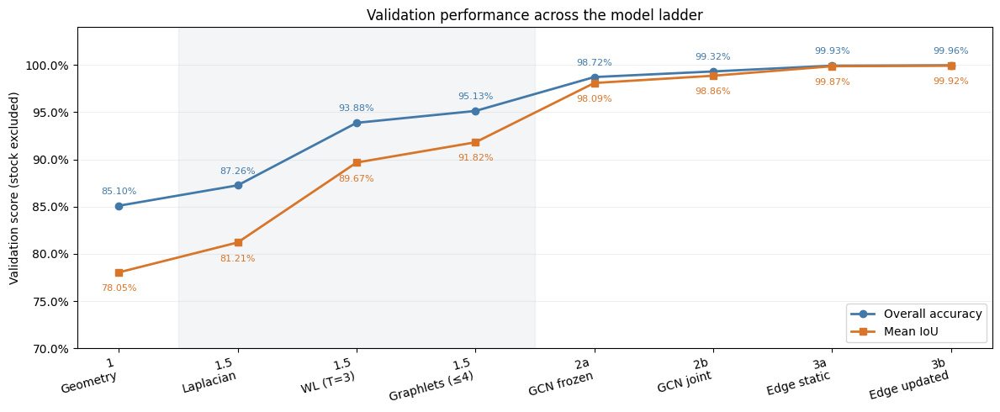

In [1]:
%matplotlib inline
%run scripts/analysis_results.py
result_class_metrics = load_analysis_metrics()
plot_nonstock_iou(result_class_metrics);

Two major jumps stand out. First, expressive topology descriptors raise non-stock mean IoU from 78.05% for geometry alone to 89.67% with WL and 91.82% with graphlets, compared with the more modest gain to 81.21% from Laplacian features. Second, learned message passing raises it further to 98.09% with a frozen CNN and 98.86% with joint training. Edge conditioning then resolves much of the remaining error, approaching saturation at 99.87–99.92%. Accuracy follows the same broad pattern, while IoU makes the remaining differences more visible.

### Stock

Stock performance is saturated: every model has fewer than ten false positives and false negatives, so we do not interpret these small single-run differences.

In [2]:
show_stock_table(result_class_metrics);

,IoU,False positives,False negatives
Model,,,
Geometry,99.9804%,4,0
Laplacian,100.0000%,0,0
WL (T=3),99.9951%,1,0
Graphlets (≤4),99.9951%,0,1
GCN frozen,99.9707%,6,0
GCN joint,99.9560%,8,1
Edge static,100.0000%,0,0
Edge updated,100.0000%,0,0


### Per-class performance

In [3]:
show_class_metrics(result_class_metrics);

IoU


Model,Geometry,Laplacian,WL (T=3),Graphlets (≤4),GCN frozen,GCN joint,Edge static,Edge updated
Class,,,,,,,,
rectangular pocket,70.77%,71.77%,92.98%,88.03%,98.68%,99.44%,99.85%,99.96%
triangular pocket,62.66%,69.24%,99.71%,98.84%,99.30%,99.69%,99.97%,100.00%
6sides pocket,79.90%,84.29%,99.78%,93.41%,99.68%,99.90%,100.00%,99.99%
rectangular passage,70.35%,72.56%,78.45%,82.66%,96.61%,97.48%,99.34%,99.70%
triangular passage,49.36%,60.25%,66.62%,96.47%,84.82%,91.73%,99.23%,99.77%
6sides passage,76.05%,80.24%,85.64%,93.81%,93.21%,96.96%,99.85%,99.91%
rectangular blind slot,60.29%,59.86%,81.56%,82.00%,99.95%,99.48%,100.00%,100.00%
rectangular through slot,71.27%,72.31%,72.35%,76.63%,99.76%,99.69%,100.00%,100.00%
triangular through slot,99.42%,99.53%,99.53%,99.58%,100.00%,99.89%,100.00%,99.95%


Recall (per-class accuracy)


Model,Geometry,Laplacian,WL (T=3),Graphlets (≤4),GCN frozen,GCN joint,Edge static,Edge updated
Class,,,,,,,,
rectangular pocket,89.21%,88.25%,98.88%,95.91%,99.46%,99.68%,100.00%,100.00%
triangular pocket,77.56%,83.28%,99.97%,99.90%,99.84%,100.00%,100.00%,100.00%
6sides pocket,91.12%,93.59%,99.97%,97.77%,99.75%,100.00%,100.00%,100.00%
rectangular passage,81.66%,84.33%,87.74%,91.34%,97.43%,98.56%,99.36%,99.73%
triangular passage,58.29%,73.77%,77.29%,97.96%,96.78%,93.70%,99.80%,99.97%
6sides passage,88.79%,87.70%,93.90%,95.74%,94.59%,99.49%,99.99%,99.97%
rectangular blind slot,74.45%,71.99%,87.53%,92.74%,99.95%,99.61%,100.00%,100.00%
rectangular through slot,78.98%,78.63%,83.04%,84.50%,99.93%,99.83%,100.00%,100.00%
triangular through slot,99.95%,99.84%,99.79%,99.84%,100.00%,100.00%,100.00%,100.00%


The class-level results offer more insight into where the models improve, but the many numbers make the patterns difficult to digest. Grouping classes by machining-feature type and profile shape makes these patterns easier to see.

### Feature type and profile shape

Each line gives the mean class IoU within a feature-type or profile-shape group, using the EDA definitions and excluding stock.

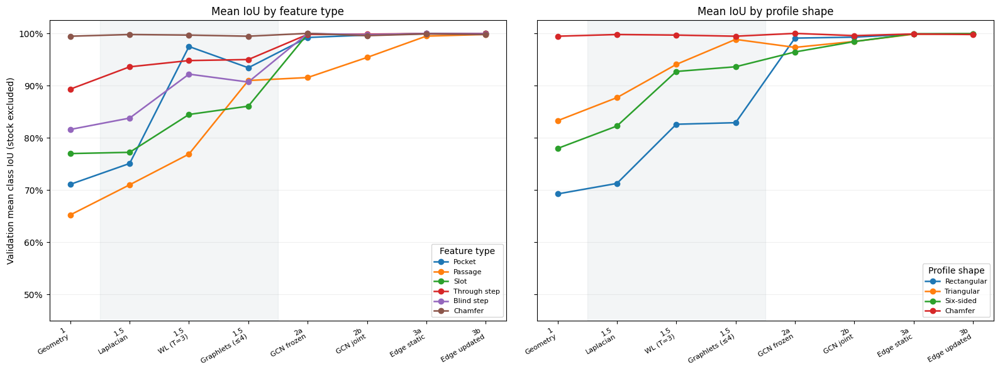

In [4]:
group_iou = plot_group_iou(result_class_metrics);

Passages and pockets are the weakest feature types for geometry alone, while chamfer is already almost perfectly classified. Shallow topology improves both, but passages retain the largest gap after GCN message passing; edge conditioning closes most of that gap.

By profile shape, rectangular features gain relatively little from Laplacian coordinates and remain below 83% mean IoU with WL or graphlets, before reaching over 99% with GCN message passing. Triangular features benefit strongly from graphlets, reaching 98.85%, slightly above either GCN variant. Thus, the aggregate improvement is not uniform across groups or strictly monotonic at every stage.

These scores show where performance improves. We next examine the face representations to see how class separation changes across the models.

## Embedding visualization

The performance gains raise the question of how the class representations change across the models.

[t-SNE working notebook](../working/analysis_tsne.ipynb)

Because t-SNE is computationally expensive, we use a subset rather than the full validation set. The same **36,714 faces** appear in every panel: all **7,533 faces misclassified by Geometry, GCN joint or Edge updated**, plus **29,181 faces classified correctly by all three**, sampled using a fixed per-class target. This retains every error from these models alongside a larger set of correct examples, deliberately emphasizing errors rather than reproducing the validation class proportions.

### Pre-classifier representations

The first comparison uses the complete representations supplied to each classifier. For the shallow models, these concatenate geometry with the topology descriptor. Each representation is reduced independently to **50 principal components**, followed by t-SNE with the same settings and seed. WL uses centred sparse PCA on its full geometry-plus-one-hot input.

| Model | Original dimension | PCA components |
| --- | ---: | ---: |
| Geometry | 64 | 50 |
| Laplacian | 72 | 50 |
| WL (T=3) | 128,253 | 50 |
| Graphlets (≤4) | 79 | 50 |
| GCN joint | 64 | 50 |
| Edge updated | 64 | 50 |

The six models occupy fixed positions in both figures. Look at which classes mix together or form separate groups in each plot. Cluster positions, directions and distances between groups can change between plots and should not be compared directly.

<Figure size 640x480 with 0 Axes>

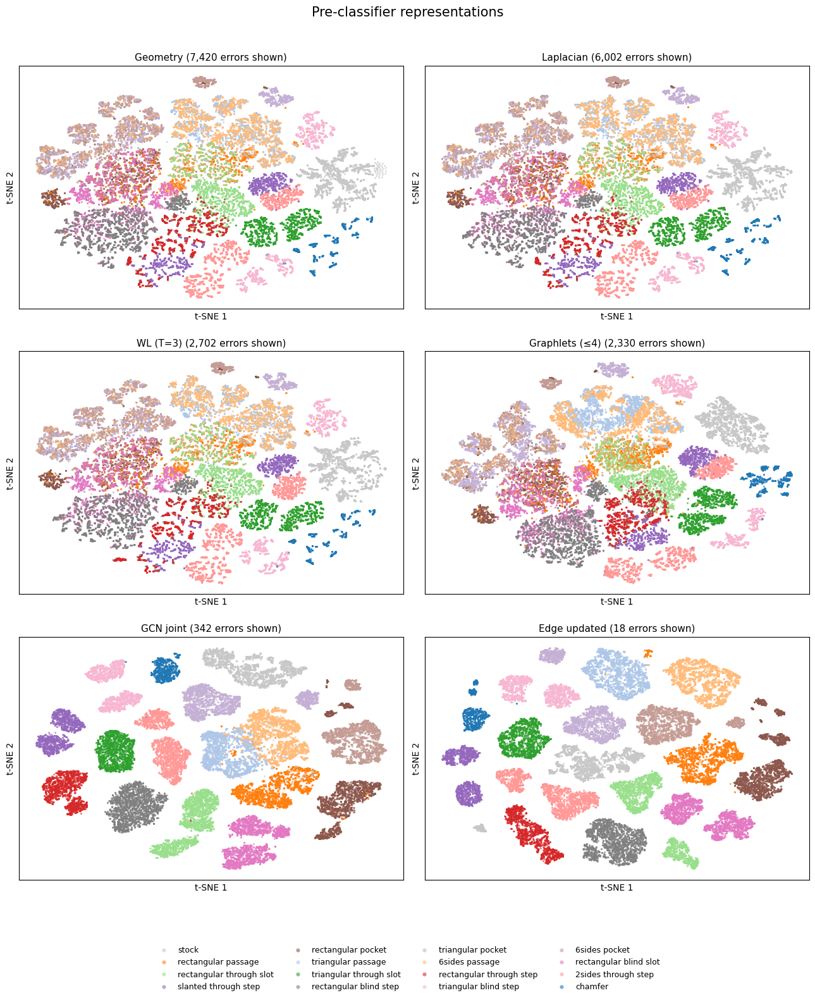

In [5]:
%matplotlib inline
%run scripts/analysis_tsne.py
embedding_cache = load_tsne_cache()
plot_tsne("pre_classifier", embedding_cache);

In the Geometry panel, **triangular pockets (pale purple) and six-sided pockets (tan)** are entangled in the upper-left islands, while **triangular passages (light blue) and six-sided passages (light orange)** mix in the upper-right region. Rectangular passages (orange) overlap rectangular through slots (light green), and the pink/brown/dark-grey region mixes rectangular blind slots, rectangular pockets and rectangular blind steps.

The full-input Laplacian and WL views retain much of this mixing. GCN separates most pocket, slot and step groups more clearly, but triangular and six-sided passages remain visibly entangled. The updated-edge representation largely separates this passage pair as well.

### Shallow first-layer representations

The raw-input plots show little apparent improvement in class separation for some shallow models, despite their clear gains in classification performance. PCA is sensitive to feature scaling. Our concatenated inputs combine geometry and topology features with different dimensions, scales and meanings, so their variance does not necessarily reflect their importance to classification. The first classifier layer learns how to weight and combine these features, giving a more informative view of their contribution.

To examine the representation after the classifier has learned how to combine these inputs, we replace the three shallow-model inputs with their **128-dimensional activations after the first classifier linear layer and ReLU**. Geometry, GCN joint and Edge updated retain their original 64-dimensional representations and coordinates. Each shallow activation is again reduced to 50 principal components before t-SNE.

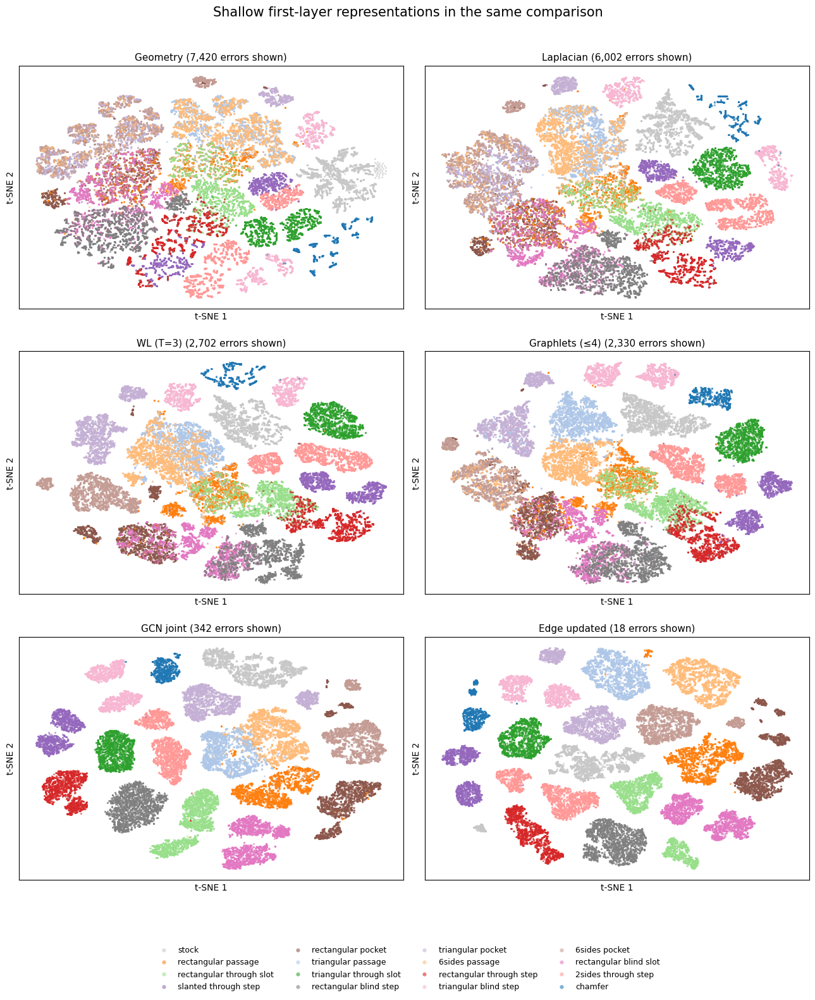

In [6]:
plot_tsne("first_layer", embedding_cache);

After the first classifier layer, WL separates triangular pockets from six-sided pockets much more clearly, although triangular and six-sided passages still share a large mixed region. Graphlets separates the passage pair more clearly than WL, while pocket classes and rectangular blind slots/steps remain partly entangled. Rectangular passages and rectangular through slots also remain mixed in the shallow-model views.

These are visual indications rather than evidence of classification errors by themselves. We will check the named class pairs in the confusion analysis to establish how the errors are distributed and which model transitions resolve them.

## Difficult classes and uncertain faces

The embeddings suggest where classes remain entangled. We examine the five classes with the lowest geometry-only IoU, selected once and followed across the same models, alongside individual uncertain faces.

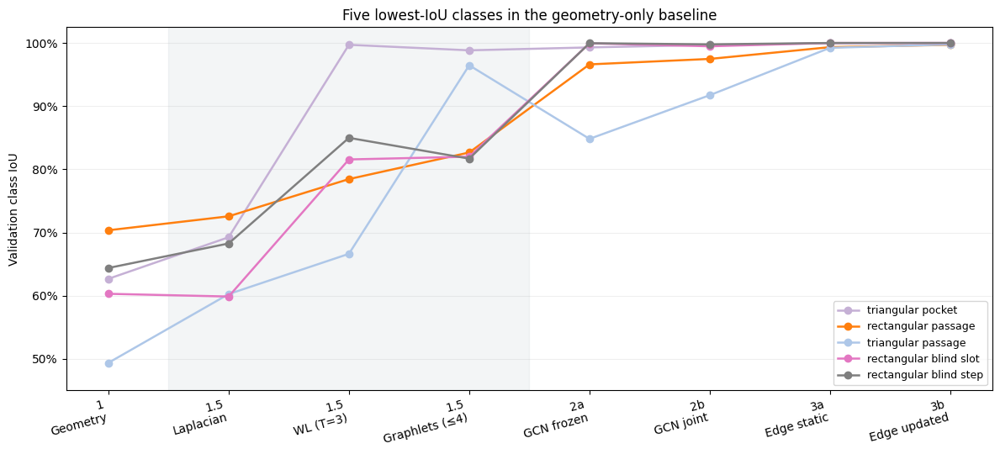

In [7]:
hardest_five_iou = plot_hardest_five_iou(result_class_metrics);

Triangular pockets improve strongly with WL and graphlets, while rectangular blind slots and blind steps gain most when learned message passing is introduced. Triangular passage is a useful exception to the aggregate ordering: graphlets outperform both GCN variants on this class before edge conditioning improves it further.

The five hardest classes alone reveal little about which classes they are confused with or which confusions later models resolve; we examine these error transitions through confusion breakdowns.

### Most uncertain faces in the updated-edge model

To inspect uncertainty in the final model, we rank validation faces by their **predictive entropy**:

$$H(\mathbf p_f)=-\sum_{c=1}^{16}p_{fc}\log p_{fc}.$$

This ranking uses only the predicted probabilities, with no correctness filter. High entropy indicates uncertainty across classes; a confidently wrong prediction can have low entropy. We show the ten highest-entropy faces and visualize the highest-entropy face within its solid.

In [8]:
uncertain_edge_faces = show_uncertain_edge_faces();

,Solid,Face,True class,Predicted class,Correct,Confidence,Entropy (nats)
Rank,,,,,,,
1,1-1-1-1-2-23_color,30,rectangular passage,6sides passage,False,58.8%,0.9630
2,0-2-2-2-14-23_color,22,rectangular passage,rectangular passage,True,54.3%,0.9044
3,0-3-8-14-14-23_color,5,slanted through step,2sides through step,False,72.0%,0.8878
4,0-2-2-2-14-23_color,7,rectangular passage,rectangular passage,True,66.5%,0.8579
5,0-2-2-2-14-23_color,24,rectangular passage,rectangular passage,True,69.0%,0.8109
6,1-2-3-14-14-23_color,37,rectangular passage,rectangular passage,True,65.8%,0.7884
7,1-2-3-14-14-23_color,38,rectangular passage,6sides passage,False,71.1%,0.7671
8,2-2-2-3-3-23_color,20,6sides passage,6sides pocket,False,50.6%,0.7329
9,2-2-2-3-3-23_color,21,6sides passage,6sides passage,True,51.9%,0.7248


In [9]:
plot_uncertain_edge_face(uncertain_edge_faces.loc[1]);

Rectangular passages retain some uncertainty even in the final edge-conditioned model, usually due to confusion with six-sided passages.

The highest-entropy face shown above is oblique, unlike most rectangular-passage faces, and intersections with triangular passages at both ends interrupt its usual through-feature geometry. These disruptions to the usual orientation and shape cues offer a plausible explanation for its remaining ambiguity.

## What does each stage correct?

The difficult classes and uncertain-face example suggest possible geometric and contextual explanations. We examine these patterns through comparisons between **adjacent stages of the model ladder**, selecting faces that change from **wrong in the source model to correct in the target model**:

- **Shallow topology:** Geometry wrong and the selected Laplacian, WL or graphlet model correct.
- **GCN:** Graphlet-4 wrong and the frozen or joint GCN correct.
- **Edge conditioning:** Joint GCN wrong and the static or updated edge model correct.

These models are not perfectly comparable, and a later model can introduce new errors as well as correct earlier ones. We interpret the adjacent-stage comparisons as a progression under the assumption that newly introduced errors form a minority, so the corrected faces help indicate what each added capability resolves. The subsets show corrections rather than net gains.

Stock faces are excluded. Variants within each stage are parallel comparisons, so their corrected subsets can overlap. The count below each box is the number of corrected faces.

In [10]:
%run scripts/analysis_corrections.py
correction_analysis = correction_properties()

<Figure size 640x480 with 0 Axes>

### Geometry: face size and elongation

**Hypothesis:** added graph information may benefit faces differently according to their size and elongation. We compare these properties between geometry-only correct and wrong faces, then examine the subsets corrected at each transition without assuming that smaller or more elongated faces must benefit more.

We use span-based proxies for **surface area** and **aspect ratio**: the longest XYZ span multiplied by the shortest non-zero span approximates face size, while their ratio describes elongation. We also examine the shortest non-zero span itself. All spans are calculated from valid surface samples. These coordinate-based measures depend on face orientation and are not exact surface areas or intrinsic aspect ratios. Each row compares geometry-only correct/wrong faces on the left with the transition-corrected subsets on the right.

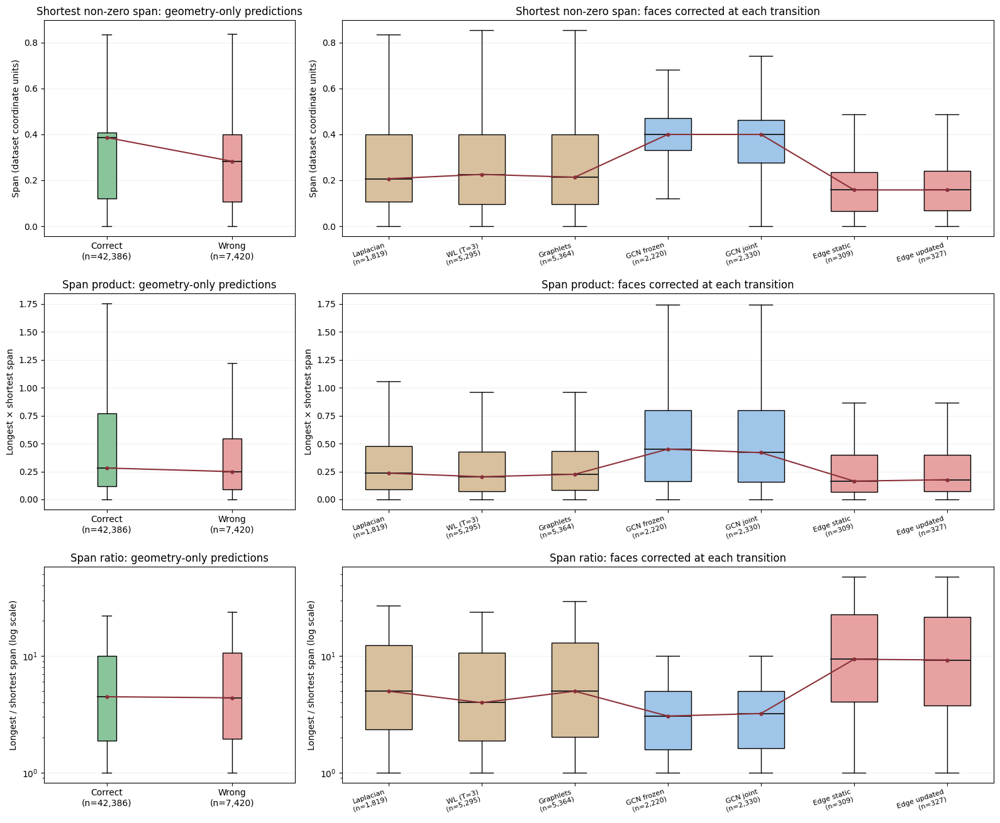

In [11]:
plot_correction_distributions(correction_analysis, [
    ("shortest_span", "Shortest non-zero span", "Span (dataset coordinate units)", False),
    ("span_product", "Span product", "Longest × shortest span", False),
    ("span_ratio", "Span ratio", "Longest / shortest span (log scale)", True),
]);

**Shortest span.** Geometry-only errors have a smaller median span than correct predictions (0.283 versus 0.387). The corrected subsets shift from narrow faces for shallow topology (medians 0.21–0.23), to wider faces for GCN (0.40), and back to narrow faces for edge conditioning (0.158).

**Surface-area proxy (span product).** Geometry-only errors also have a modestly smaller median area proxy (0.249 versus 0.281). Corrected-face medians follow a similar rise and fall: 0.20–0.24 for shallow models, 0.42–0.45 for GCN and 0.16–0.18 for edge models.

**Aspect-ratio proxy (span ratio).** Geometry-only correct and wrong faces have similar median aspect-ratio proxies (4.48 and 4.39). Edge-stage corrections have medians above 9, compared with roughly 3–5 for earlier corrections.

The architectural changes add graph information, so these shifts should not be read as evidence that one graph variant directly handles small or elongated faces better. Instead, incorporating graph structure—and later boundary geometry—may preferentially benefit structural patterns associated with certain face geometries. For example, correcting more passage faces could shift the span distributions because passage structure and face extent are correlated. These plots describe that association, without isolating geometry as the cause of the improvement.

### Normal alignment

**Hypothesis:** normal alignment is a class-dependent geometric cue, so added graph information may benefit axis-aligned and oblique faces differently. We compare the proportion of non-axis-aligned faces among the corrected subsets.

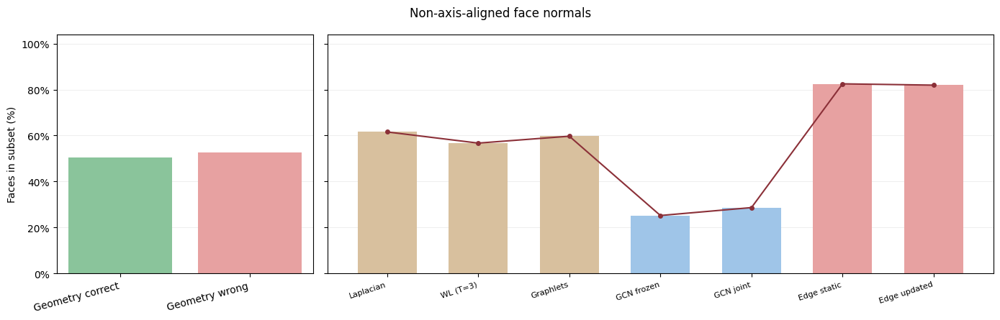

In [12]:
plot_binary_correction_property(correction_analysis, "non_axis_aligned", "Non-axis-aligned face normals");

Oblique faces account for 52.5% of geometry-only errors and 50.6% of correct predictions. The similar proportions indicate that geometry-only errors show little overall bias towards oblique faces. Shallow corrections are more enriched in oblique faces (56.7–61.6%), while most GCN corrections are axis-aligned. Around 82% of edge corrections are oblique, consistent with the difficult example above, although the source-error pool is already 81.8% oblique. Taken together with the span results above, these patterns relate face geometry to the subsets corrected after adding graph information, but show no consistent one-way trend. Their composition also depends on which errors remain at each stage, so a high proportion alone does not establish a preferential benefit for that subset.

### Graph context: two- and three-hop neighbourhoods

**Hypothesis:** added graph information may benefit faces differently according to the size of their surrounding neighbourhood. We compare corrected subsets by counting the unique other faces reachable within two and three hops, without assuming that the benefit must favour larger neighbourhoods.

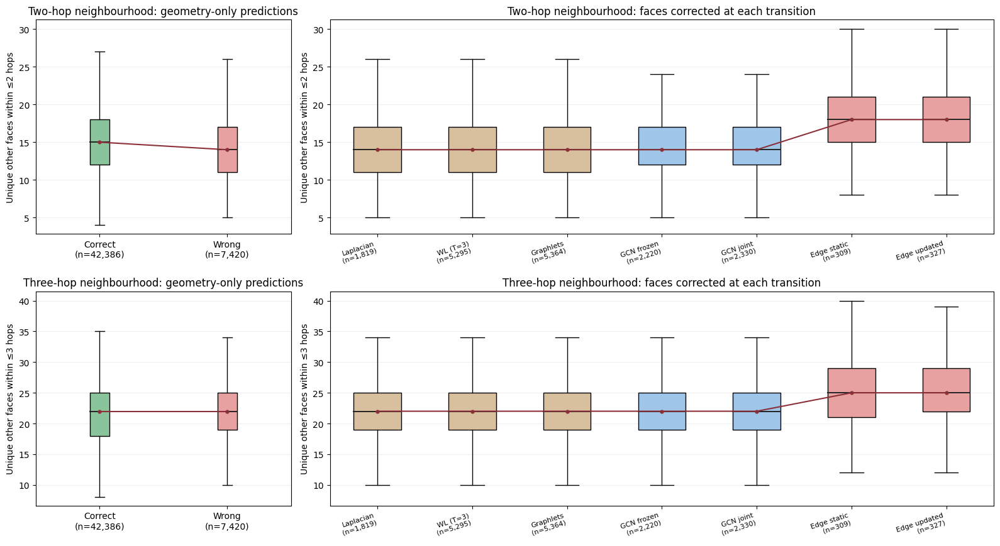

In [13]:
plot_correction_distributions(correction_analysis, [
    ("two_hop", "Two-hop neighbourhood", "Unique other faces within ≤2 hops", False),
    ("three_hop", "Three-hop neighbourhood", "Unique other faces within ≤3 hops", False),
]);

The geometry-only correct and wrong populations have similar neighbourhood sizes: median two-hop counts are 15 and 14, and both three-hop medians are 22. Shallow and GCN corrections also have medians of 14 and 22, whereas edge corrections shift upwards to 18 and 25.

These results suggest that graph neighbourhood context contributes to distinguishing more difficult machining features, but its impact on corrections in larger neighbourhoods only becomes apparent at the edge-conditioned stage.

### Boundary degree other than four

**Hypothesis:** added graph information may benefit degree-four and non-degree-four faces differently. We use four as the reference because it is the modal degree in the EDA and corresponds to the common rectangular face with four boundaries. We compare the proportion of corrected faces whose boundary degree differs from four.

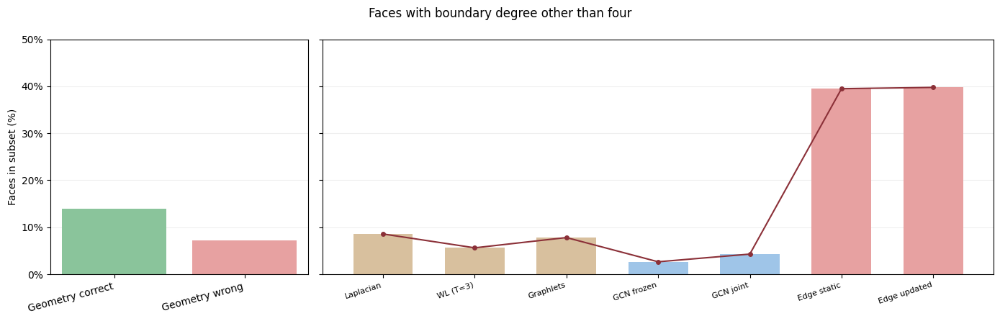

In [14]:
plot_binary_correction_property(correction_analysis, "non_four_degree", "Faces with boundary degree other than four");

Departures from the common degree-four rectangular-face pattern account for 7.2% of geometry-only errors and 13.9% of correct predictions, so they are not disproportionately represented among baseline errors. GCN corrections remain overwhelmingly within the degree-four population, consistent with resolving ambiguities that boundary counting alone cannot distinguish. By the edge stage, about 40% of corrected faces depart from this common pattern, closely matching the remaining source-error pool (40.2%). Edge conditioning therefore helps resolve a residual population containing many faces with less typical boundary structure.

These distributions show how the corrected populations differ across the ladder, without establishing a universal direction of benefit. The shifts may reflect graph properties correlated with geometry—for example, resolving passage errors can change the span and ratio distributions—as well as changes in the remaining error pool. Like the hardest-class chart and individual difficult faces, these summaries cannot tell us exactly which classes are confused with which. We therefore turn next to class-to-class confusion breakdowns and trace which of those mistakes each model transition fixes.

## Which confusions does each transition fix?

The property distributions show how corrected subsets differ across stages, but do not reveal which classes are confused with which. Class-to-class corrections offer a more specific view of these patterns.

For each transition, we select non-stock faces that the source model gets wrong and the target model gets right. Rows give their true class; columns give the source model’s earlier wrong prediction. Percentages describe the distribution of those earlier mistakes within each corrected class and sum to 100% for rows with at least one correction. Zero-correction rows remain visible to preserve class alignment and make reciprocal patterns easier to compare.

The count columns give the Geometry baseline errors, source-model errors and number fixed by the target. To avoid emphasizing percentages based on very few faces, heatmap colouring is applied only when **Fixed > 100** in the first two comparisons and **Fixed > 30** in the third. Lower-support rows remain visible in neutral grey. 

### Geometry → Graphlets

In [15]:
geometry_graphlet_confusion = show_transition_confusion("Geometry", "Graphlets (≤4)", minimum_fixed=100);

,Geometrybaselineerrors,Geometryerrors,Fixed,stock,rectangular pocket,triangular pocket,6sides pocket,rectangular passage,triangular passage,6sides passage,rectangular blind slot,rectangular through slot,triangular through slot,rectangular through step,2sides through step,slanted through step,rectangular blind step,triangular blind step,chamfer
Correct class,,,,,,,,,,,,,,,,,,,
rectangular pocket,501,501,333,0.0%,0.0%,61.3%,7.8%,0.3%,0.0%,0.0%,30.6%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
triangular pocket,859,859,856,0.0%,21.8%,0.0%,76.2%,0.0%,0.0%,0.0%,1.4%,0.0%,0.0%,0.0%,0.6%,0.0%,0.0%,0.0%,0.0%
6sides pocket,604,604,454,0.0%,9.5%,89.6%,0.0%,0.0%,0.0%,0.9%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
rectangular passage,805,805,494,0.0%,59.1%,0.8%,0.4%,0.0%,4.7%,9.1%,15.4%,6.9%,0.0%,0.0%,0.0%,0.0%,1.0%,2.6%,0.0%
triangular passage,"1,245","1,245","1,186",0.0%,0.1%,1.7%,0.5%,11.9%,0.0%,85.1%,0.2%,0.5%,0.0%,0.0%,0.0%,0.0%,0.0%,0.1%,0.0%
6sides passage,763,763,495,0.0%,0.0%,3.0%,9.3%,4.6%,81.8%,0.0%,0.2%,0.8%,0.0%,0.0%,0.0%,0.0%,0.0%,0.2%,0.0%
rectangular blind slot,975,975,736,0.0%,51.8%,2.3%,0.1%,4.1%,0.1%,0.0%,0.0%,0.4%,0.0%,0.5%,0.1%,0.0%,40.5%,0.0%,0.0%
rectangular through slot,606,606,189,0.0%,0.0%,0.0%,0.0%,46.0%,9.5%,0.5%,0.0%,0.0%,0.5%,43.4%,0.0%,0.0%,0.0%,0.0%,0.0%
triangular through slot,1,1,0,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%


Many corrected confusions occur in reciprocal pairs, giving an approximately symmetric pattern about the class diagonal, with some exceptions. These include different pocket shapes, triangular versus six-sided passages, pockets versus slots, and slots versus steps. Such distinctions often have simple degree signatures: the number of edges around a face and the degrees of its neighbours help identify the feature structure. The shallow-topology gains are therefore consistent with resolving geometric ambiguity through local degree patterns. The symmetry concerns which class pairs are confused, rather than equal percentages in both directions, since each row is normalised separately.

### Graphlets → Joint GCN

In [16]:
graphlet_gcn_confusion = show_transition_confusion("Graphlets (≤4)", "GCN joint", minimum_fixed=100);

,Geometrybaselineerrors,Graphlets(≤4)errors,Fixed,stock,rectangular pocket,triangular pocket,6sides pocket,rectangular passage,triangular passage,6sides passage,rectangular blind slot,rectangular through slot,triangular through slot,rectangular through step,2sides through step,slanted through step,rectangular blind step,triangular blind step,chamfer
Correct class,,,,,,,,,,,,,,,,,,,
rectangular pocket,501,190,182,0.0%,0.0%,0.0%,73.1%,0.5%,0.0%,0.0%,25.3%,0.0%,0.0%,0.0%,1.1%,0.0%,0.0%,0.0%,0.0%
triangular pocket,859,4,4,0.0%,25.0%,0.0%,75.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
6sides pocket,604,152,152,0.0%,98.0%,0.7%,0.0%,0.0%,0.0%,1.3%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
rectangular passage,805,380,332,0.0%,23.5%,0.3%,2.1%,0.0%,1.2%,23.5%,12.0%,35.2%,0.6%,0.3%,0.0%,0.0%,1.2%,0.0%,0.0%
triangular passage,"1,245",61,43,0.0%,0.0%,72.1%,0.0%,11.6%,0.0%,16.3%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
6sides passage,763,290,282,0.0%,0.4%,0.0%,58.5%,27.7%,11.3%,0.0%,0.4%,1.8%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
rectangular blind slot,975,277,274,0.0%,66.8%,0.0%,0.7%,2.6%,0.0%,0.0%,0.0%,1.5%,0.0%,0.4%,0.0%,0.0%,28.1%,0.0%,0.0%
rectangular through slot,606,447,444,0.0%,0.0%,0.0%,0.0%,80.6%,0.0%,1.1%,0.2%,0.0%,0.0%,18.0%,0.0%,0.0%,0.0%,0.0%,0.0%
triangular through slot,1,3,3,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,33.3%,0.0%,0.0%,66.7%


After shallow topology resolves much of the shape confusion through degree patterns, the remaining errors become more asymmetric. Among the mistakes corrected by GCN, two parallel chains stand out: rectangular through step → rectangular through slot → rectangular passage, and rectangular blind step → rectangular blind slot → rectangular pocket. Each arrow denotes a true class being mistaken for the next class. Passage errors are spread across several feature types. Some pocket-shape confusion remains, particularly between rectangular and six-sided pockets, but the dominant pattern shifts towards distinguishing feature types whose individual faces can look similar. Learned message passing helps resolve these ambiguities by combining geometry with fuller neighbourhood context beyond degree counts.

### Joint GCN → Updated edges

In [17]:
gcn_edge_confusion = show_transition_confusion("GCN joint", "Edge updated", minimum_fixed=30);

,Geometrybaselineerrors,GCNjointerrors,Fixed,stock,rectangular pocket,triangular pocket,6sides pocket,rectangular passage,triangular passage,6sides passage,rectangular blind slot,rectangular through slot,triangular through slot,rectangular through step,2sides through step,slanted through step,rectangular blind step,triangular blind step,chamfer
Correct class,,,,,,,,,,,,,,,,,,,
rectangular pocket,501,15,15,0.0%,0.0%,33.3%,40.0%,26.7%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
triangular pocket,859,0,0,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
6sides pocket,604,0,0,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
rectangular passage,805,63,53,7.5%,11.3%,13.2%,0.0%,0.0%,56.6%,11.3%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
triangular passage,"1,245",188,187,0.0%,0.0%,0.0%,0.0%,11.2%,0.0%,88.8%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
6sides passage,763,35,34,0.0%,0.0%,0.0%,0.0%,17.6%,82.4%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
rectangular blind slot,975,15,15,0.0%,20.0%,0.0%,0.0%,80.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
rectangular through slot,606,5,5,0.0%,0.0%,0.0%,0.0%,100.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
triangular through slot,1,0,0,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%


The remaining high-support confusions return mainly to passage shape, especially triangular versus six-sided passages. Both commonly have oblique walls, so obliqueness alone cannot distinguish them; the relative angles and arrangement of those walls matter. Intersections can further alter the usual boundary counts, as illustrated by the earlier passage example.

One possible explanation for the edge model’s improvement is that sampled boundary positions and tangents make the relationships between neighbouring faces more explicit. A GCN could also learn relative-angle information from the face normals, potentially through additional layers that combine a fuller neighbourhood, whereas edge conditioning directly supplies boundary geometry to the message computation. This offers a possible route to distinguishing the passage cross-sections, rather than a confirmed mechanism.

## Visualizing corrections across the model ladder

Let’s visualize corrections using a few whole-solid examples across the model ladder.

To try to find a representative example for each transition, we select the solid with the largest reduction in mean face-level cross-entropy among those the target classifies entirely correctly and the source gets partly wrong. The baseline example is the entirely correct Geometry solid with the highest mean cross-entropy, representing the one the model found most challenging to classify correctly. Red faces are source-model errors, blue faces are other machining-feature faces, and grey faces are stock. The target is correct on every face. The percentage beside mean cross-entropy is the geometric mean true-class probability; the table lists probabilities for the corrected faces.

In [18]:
show_transition_solid_examples();

,sample_id,face_count,source_model,source_error_count,source_mean_CE,source_geometric_mean_true_probability_percent,target_model,target_error_count,target_mean_CE,target_geometric_mean_true_probability_percent,mean_CE_drop
stage,,,,,,,,,,,
Baseline correct,6-9-10-12-19_color,21,Geometry,0,0.2438,78.4%,Geometry,0,0.2438,78.4%,0.0000
Graphlets correction,1-1-2-9-9-23_color,26,Geometry,12,1.0380,35.4%,Graphlets (≤4),0,0.0206,98.0%,1.0174
GCN joint correction,2-2-2-8-12-23_color,32,Graphlets (≤4),12,1.1670,31.1%,GCN joint,0,0.0149,98.5%,1.1521
Edge updated correction,1-1-3-6-12-23_color,26,GCN joint,4,0.7094,49.2%,Edge updated,0,0.0000,100.0%,0.7094


,stage,sample_id,face_index,before_model,after_model,Pred,GT,before_pred_probability_percent,before_GT_probability_percent,after_pred_GT_probability_percent
0,Graphlets correction,1-1-2-9-9-23_color,5,Geometry,Graphlets (≤4),rectangular_pocket,triangular_pocket,47.5%,46.8%,97.6%
1,Graphlets correction,1-1-2-9-9-23_color,6,Geometry,Graphlets (≤4),rectangular_pocket,triangular_pocket,57.1%,39.4%,98.6%
2,Graphlets correction,1-1-2-9-9-23_color,7,Geometry,Graphlets (≤4),rectangular_pocket,triangular_pocket,71.5%,0.5%,96.9%
3,Graphlets correction,1-1-2-9-9-23_color,9,Geometry,Graphlets (≤4),6sides_passage,triangular_passage,85.2%,14.7%,100.0%
4,Graphlets correction,1-1-2-9-9-23_color,10,Geometry,Graphlets (≤4),rectangular_blind_slot,triangular_passage,47.2%,1.1%,72.7%
5,Graphlets correction,1-1-2-9-9-23_color,11,Geometry,Graphlets (≤4),6sides_passage,triangular_passage,55.4%,41.4%,100.0%
6,Graphlets correction,1-1-2-9-9-23_color,14,Geometry,Graphlets (≤4),6sides_passage,triangular_passage,69.2%,30.1%,99.9%
7,Graphlets correction,1-1-2-9-9-23_color,15,Geometry,Graphlets (≤4),rectangular_pocket,triangular_pocket,47.1%,33.9%,96.8%
8,Graphlets correction,1-1-2-9-9-23_color,16,Geometry,Graphlets (≤4),6sides_pocket,triangular_pocket,87.8%,8.0%,99.0%
9,Graphlets correction,1-1-2-9-9-23_color,17,Geometry,Graphlets (≤4),6sides_pocket,triangular_pocket,56.7%,36.1%,99.0%


These examples support the earlier confusion analysis. Shallow topology resolves much of the confusion between feature shapes through local degree patterns. GCN message passing helps when degree counting alone is insufficient—for example, when the relevant faces are all rectangular—and when intersections disrupt the usual feature structure. Edge conditioning then resolves a particularly difficult case combining intersections with an ambiguous feature shape, where boundary geometry provides additional distinguishing cues.

---

[← Previous: Modelling](03_modelling.ipynb) | [Next: Conclusion →](05_conclusion.ipynb)